In [1]:
!pip install -q pymc3 arviz --upgrade --progress-bar off

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
!pip install -q pgmpy==0.1.20 --progress-bar off


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

# Patch missing attributes in pgmpy.global_vars
import pgmpy.global_vars
pgmpy.global_vars.SHOW_PROGRESS = False
pgmpy.global_vars.device = None  # Add missing attribute
pgmpy.global_vars.dtype = None   # Add missing attribute

from pgmpy.models import BayesianModel
from pgmpy.estimators import BayesianEstimator, HillClimbSearch, BicScore

import pymc as pm

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [4]:
df = pd.read_csv('/kaggle/input/phiusiil-phishing-url-website/PhiUSIIL_Phishing_URL_Dataset.csv')  
print(df.shape)
df.head()

(235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [5]:
print(df.isna().sum().sort_values(ascending=False).head(10))
print(df['label'].value_counts())
df.describe(include='all').T.head()

FILENAME                0
URL                     0
URLLength               0
Domain                  0
DomainLength            0
IsDomainIP              0
TLD                     0
URLSimilarityIndex      0
CharContinuationRate    0
TLDLegitimateProb       0
dtype: int64
label
1    134850
0    100945
Name: count, dtype: int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FILENAME,235795,235795,384822.txt,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
URL,235795,235370,https://jauntyimprobableautomaticvectorization...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
URLLength,235795.0,NaN,NaN,NaN,34.573095,41.314153,13.0,23.0,27.0,34.0,6097.0
Domain,235795,220086,ipfs.io,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DomainLength,235795.0,NaN,NaN,NaN,21.470396,9.150793,4.0,16.0,20.0,24.0,110.0


# Conventional Naïve Bayes baseline

In [6]:
X = df.drop(columns=['label', 'FILENAME', 'URL', 'Title'])   # strip non-predictive IDs / free-text
y = df['label']

# Identify non-numeric columns and drop them
non_numeric_cols = X.select_dtypes(exclude=[np.number]).columns
print(f"Dropping non-numeric columns: {list(non_numeric_cols)}")
X = X.drop(columns=non_numeric_cols)


nb_pipe = Pipeline([
    ('scaler', StandardScaler(with_mean=False)),  # NB benefits from variance stabilisation
    ('nb', GaussianNB())
])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
f1_scores = cross_val_score(nb_pipe, X, y, cv=cv, scoring='f1')
print(f"Naïve Bayes CV F1 = {f1_scores.mean():.3f} ± {f1_scores.std():.3f}")

# Fit once to inspect posterior probabilities for one fold
nb_pipe.fit(X, y)
y_pred = nb_pipe.predict(X)
print(classification_report(y, y_pred))

Dropping non-numeric columns: ['Domain', 'TLD']
Naïve Bayes CV F1 = 1.000 ± 0.000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    100945
           1       1.00      1.00      1.00    134850

    accuracy                           1.00    235795
   macro avg       1.00      1.00      1.00    235795
weighted avg       1.00      1.00      1.00    235795



# Bayesian Belief Network (structure learned via Hill-Climb +BIC)

In [7]:
from pgmpy.estimators import HillClimbSearch, BicScore, BayesianEstimator
from pgmpy.models import BayesianModel
from pgmpy.inference import VariableElimination

# 1. Reduce dimensionality by selecting key features
selected_features = ['NoOfExternalRef', 'HasCopyrightInfo', 'label']  # Add other important features
subset_df = df[selected_features].copy()

# 2. Discretize continuous variables to reduce state space
subset_df['NoOfExternalRef'] = pd.cut(subset_df['NoOfExternalRef'], 
                                     bins=[0, 10, 100, np.inf],
                                     labels=['low', 'medium', 'high'])

# 3. Learn structure on a sample to reduce memory usage
sample_size = min(1000, len(subset_df))
hc = HillClimbSearch(subset_df.sample(sample_size, random_state=RANDOM_STATE))
best_model = hc.estimate(scoring_method=BicScore(subset_df),
                         max_indegree=4,  # Limit complexity
                         max_iter=100,    # Reduce iterations
                         show_progress=False)

# 4. Create and fit model
model = BayesianModel(best_model.edges())
model.fit(subset_df, 
          estimator=BayesianEstimator, 
          prior_type="BDeu", 
          equivalent_sample_size=5)  # Smaller sample size

print(f"BBN structure edges: {model.edges()}")

# 5. Inference with discretized evidence
infer = VariableElimination(model)
try:
    # Use discretized values in evidence
    phi = infer.query(['label'], evidence={'NoOfExternalRef': 'high', 'HasCopyrightInfo': 0})
    print(phi)
except Exception as e:
    print(f"Inference error: {e}")

BBN structure edges: [('NoOfExternalRef', 'label'), ('NoOfExternalRef', 'HasCopyrightInfo'), ('label', 'HasCopyrightInfo')]
+----------+--------------+
| label    |   phi(label) |
+==========+==============+
| label(0) |       0.0005 |
+----------+--------------+
| label(1) |       0.9995 |
+----------+--------------+


/usr/local/lib/python3.11/dist-packages/pgmpy/estimators/base.py:161: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby([variable] + parents).size().unstack(parents)
/usr/local/lib/python3.11/dist-packages/pgmpy/estimators/base.py:161: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby([variable] + parents).size().unstack(parents)
/usr/local/lib/python3.11/dist-packages/pgmpy/estimators/base.py:161: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the f

#  Bayesian logistic regression - Optimized for Speed

Top features used: ['URLSimilarityIndex', 'HasSocialNet', 'HasCopyrightInfo', 'HasDescription', 'IsHTTPS']


Output()

/tmp/ipykernel_19/23649500.py:47: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(3, 2, 2)
/tmp/ipykernel_19/23649500.py:54: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(3, 2, 3)
/tmp/ipykernel_19/23649500.py:58: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(3, 2, 4)
/tmp/ipykernel_19/23649500.py:76: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  plt.subplot(3, 2, 5)
/tmp/ipykernel_19/23649500.py:90: MatplotlibDeprecationWarning: Auto-removal of over

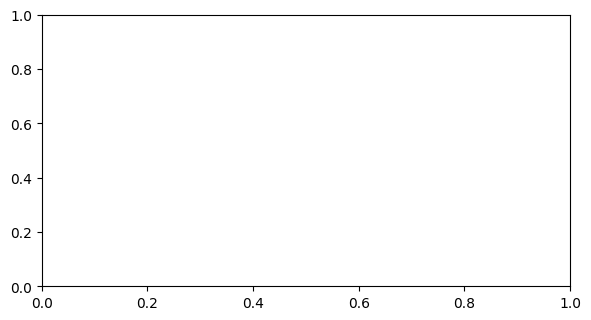

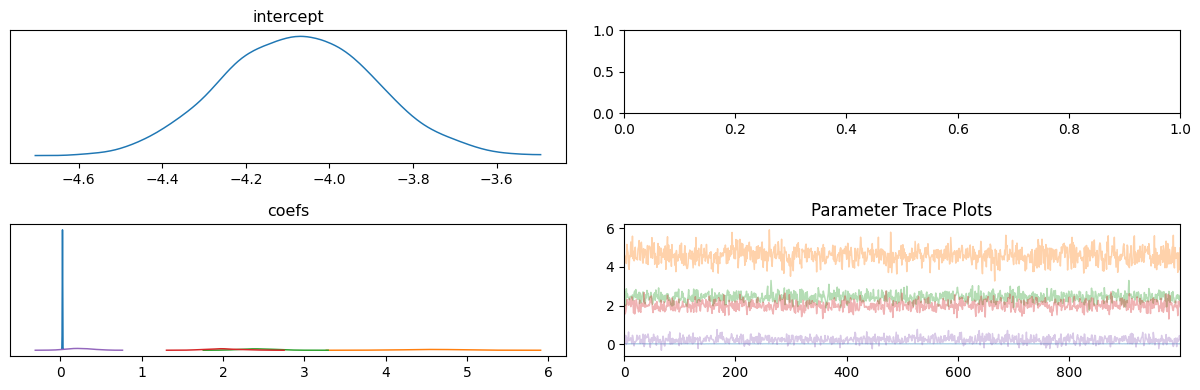

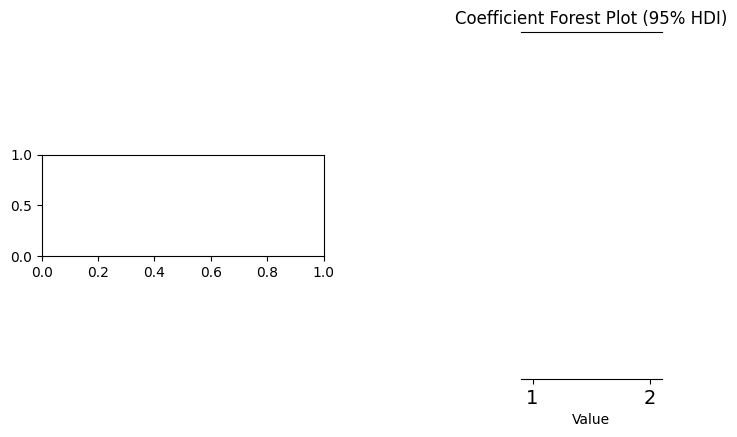

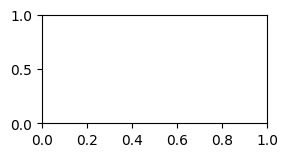

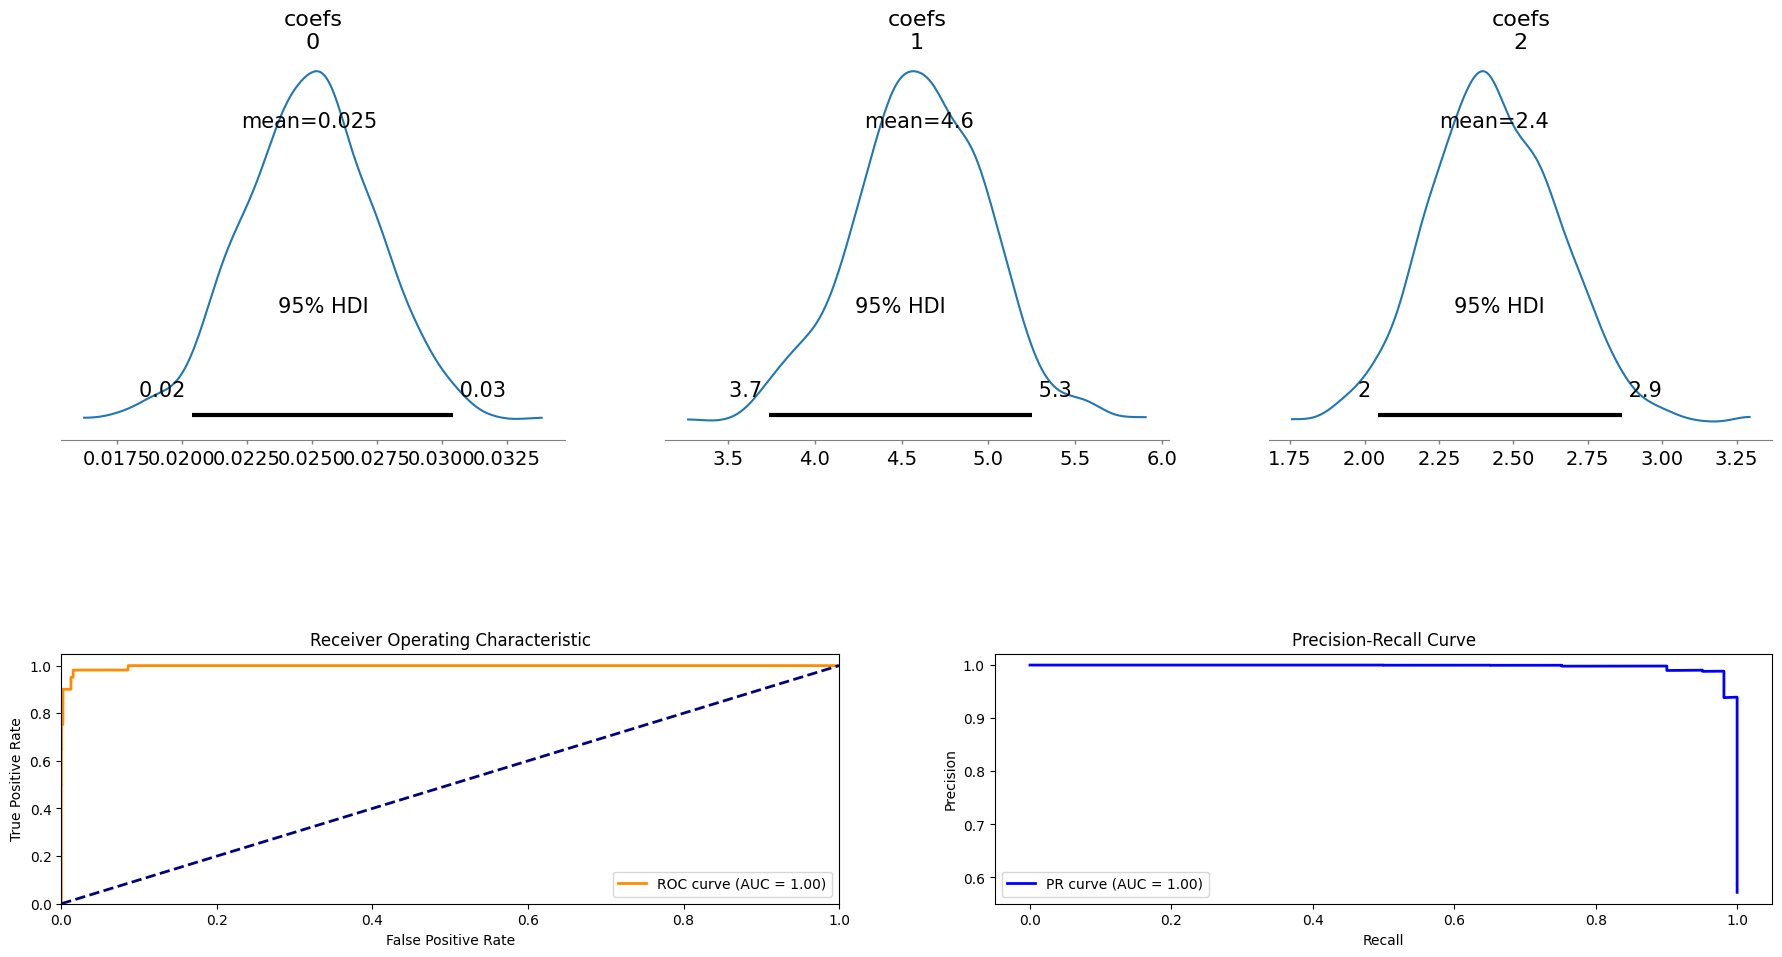

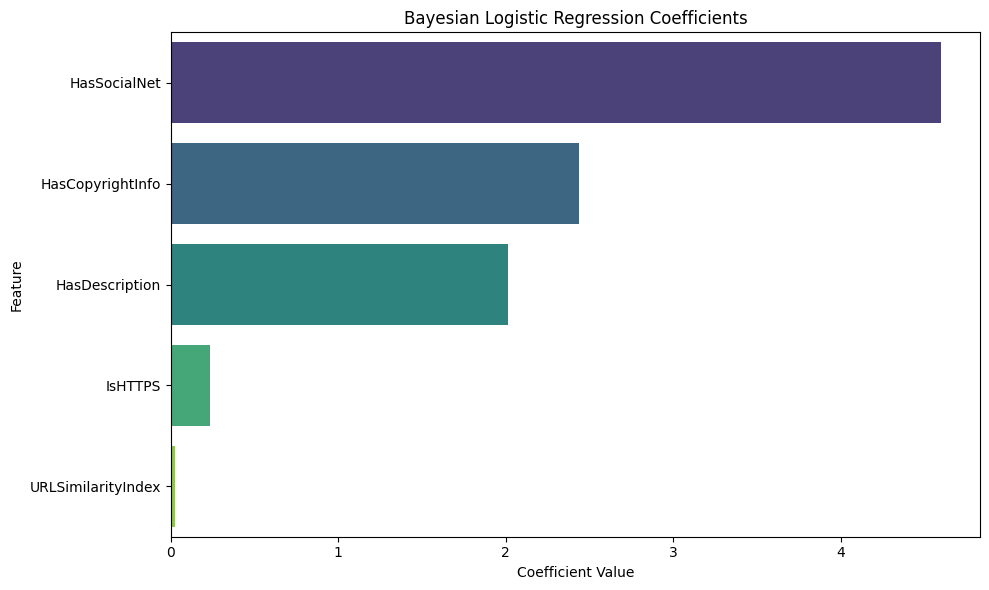

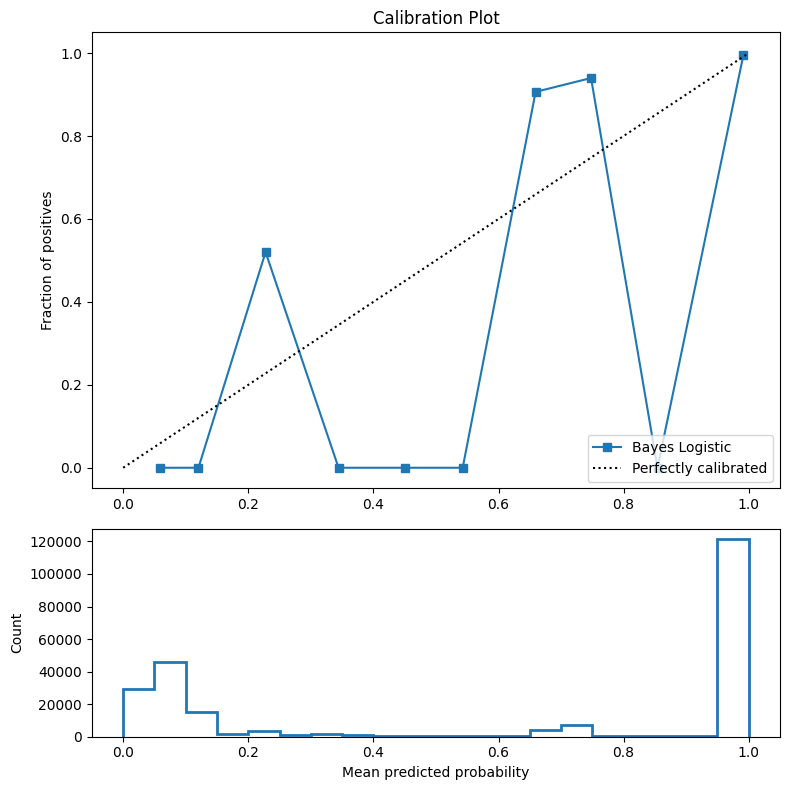


Performance Metrics:
F1 Score: 0.9810
ROC AUC: 0.9969
PR AUC: 0.9976
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.97    100945
           1       0.98      0.98      0.98    134850

    accuracy                           0.98    235795
   macro avg       0.98      0.98      0.98    235795
weighted avg       0.98      0.98      0.98    235795




In [8]:
# ──────────────────────────────────────────────────────────────
# 5. Bayesian Logistic Regression with Enhanced Visualizations
# ──────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# 1. Feature selection and data prep
top_feats = X.corrwith(y).abs().sort_values(ascending=False).head(5).index
print("Top features used:", list(top_feats))
X_top = X[top_feats].values.astype(np.float32)

# 2. Create training sample
sample_size = min(5000, len(X_top))
sample_idx = np.random.choice(len(X_top), size=sample_size, replace=False)
X_sample = X_top[sample_idx]
y_sample = y.values[sample_idx]

with pm.Model() as bayes_logit:
    # Data containers
    X_data = pm.Data('X_data', X_sample)
    y_data = pm.Data('y_data', y_sample)
    
    # Priors
    intercept = pm.Normal('intercept', mu=0, sigma=5)
    coefs = pm.Normal('coefs', mu=0, sigma=5, shape=X_sample.shape[1])
    
    # Linear model
    mu = intercept + pm.math.dot(X_data, coefs)
    theta = pm.math.sigmoid(mu)
    yl = pm.Bernoulli('yl', p=theta, observed=y_data)
    
    # Variational Inference
    approx = pm.fit(n=30000, method='advi', random_seed=RANDOM_STATE)
    trace = approx.sample(1000)

# 3. Posterior analysis
plt.figure(figsize=(15, 12))

# A. Trace plot for all parameters
plt.subplot(3, 2, 1)
az.plot_trace(trace, var_names=['intercept', 'coefs'], compact=True)
plt.title('Parameter Trace Plots')
plt.tight_layout()

# B. Forest plot of coefficients
plt.subplot(3, 2, 2)
az.plot_forest(trace, var_names=['coefs'], combined=True, hdi_prob=0.95, r_hat=True)
plt.title('Coefficient Forest Plot (95% HDI)')
plt.xlabel('Value')
plt.axvline(x=0, color='r', linestyle='--', alpha=0.3)

# C. Posterior distributions
plt.subplot(3, 2, 3)
az.plot_posterior(trace, var_names=['intercept'], hdi_prob=0.95, point_estimate='mean')
plt.title('Intercept Posterior Distribution')

plt.subplot(3, 2, 4)
az.plot_posterior(trace, var_names=['coefs'], hdi_prob=0.95, point_estimate='mean')
plt.title('Coefficients Posterior Distribution')

# 4. Prediction and performance evaluation
# Get posterior mean parameters
intercept_post = trace.posterior['intercept'].mean().item()
coefs_post = trace.posterior['coefs'].mean(axis=(0, 1)).values

# Calculate probabilities
logits = intercept_post + np.dot(X_top, coefs_post)
probs = 1 / (1 + np.exp(-logits))
y_hat = (probs > 0.5).astype(int)

# D. ROC Curve
fpr, tpr, _ = roc_curve(y, probs)
roc_auc = auc(fpr, tpr)

plt.subplot(3, 2, 5)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")

# E. Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y, probs)
pr_auc = auc(recall, precision)

plt.subplot(3, 2, 6)
plt.plot(recall, precision, color='blue', lw=2, label=f'PR curve (AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()

# 5. Feature importance plot
plt.figure(figsize=(10, 6))
coef_df = pd.DataFrame({
    'Feature': list(top_feats),
    'Coefficient': coefs_post,
    'Abs_Effect': np.abs(coefs_post)
})
coef_df = coef_df.sort_values('Abs_Effect', ascending=False)

sns.barplot(x='Coefficient', y='Feature', data=coef_df, palette='viridis')
plt.title('Bayesian Logistic Regression Coefficients')
plt.axvline(x=0, color='r', linestyle='--', alpha=0.3)
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# 6. Calibration plot
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 8))
ax1 = plt.subplot2grid((3, 1), (0, 0), rowspan=2)
ax2 = plt.subplot2grid((3, 1), (2, 0))

fraction_of_positives, mean_predicted_value = calibration_curve(y, probs, n_bins=10)

ax1.plot(mean_predicted_value, fraction_of_positives, "s-", label="Bayes Logistic")
ax1.plot([0, 1], [0, 1], "k:", label="Perfectly calibrated")
ax1.set_ylabel("Fraction of positives")
ax1.set_ylim([-0.05, 1.05])
ax1.legend(loc="lower right")
ax1.set_title('Calibration Plot')

ax2.hist(probs, range=(0, 1), bins=20, histtype="step", lw=2)
ax2.set_xlabel("Mean predicted probability")
ax2.set_ylabel("Count")
plt.tight_layout()
plt.show()

# 7. Performance metrics
print("\n" + "="*50)
print("Performance Metrics:")
print(f"F1 Score: {f1_score(y, y_hat):.4f}")
print(f"ROC AUC: {roc_auc:.4f}")
print(f"PR AUC: {pr_auc:.4f}")
print("Classification Report:")
print(classification_report(y, y_hat))
print("="*50 + "\n")

# Optimized MCTS for Feature Selection with Visualizations

Precomputing base feature scores...


Computing base scores: 100%|██████████| 50/50 [00:01<00:00, 37.66it/s]
Features: 4 | F1: 0.5542:  40%|████      | 8/20 [00:01<00:02,  5.13it/s]



MCTS-selected 4 features | F1 ≈ 0.5542
Selected features: ['feature_4', 'feature_35', 'feature_2', 'feature_25']


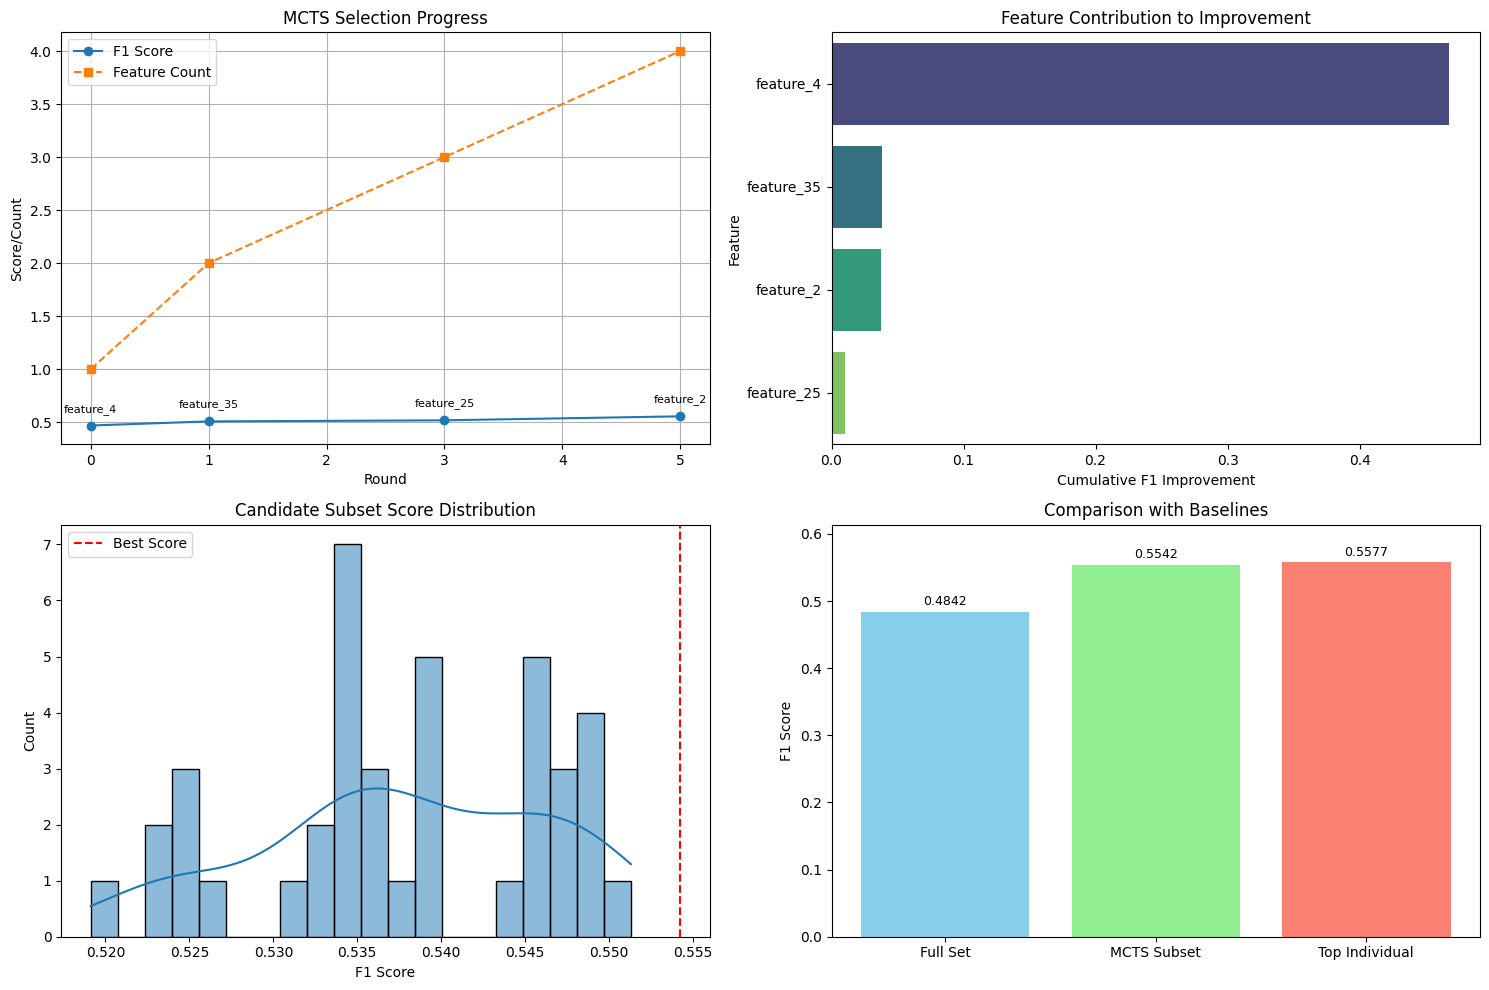


Performance Comparison:
- Full feature set (50 features): F1 = 0.4842
- MCTS selected (4 features): F1 = 0.5542
- Best single feature: F1 = 0.5577
Reduction: 46 features (92.0% fewer)


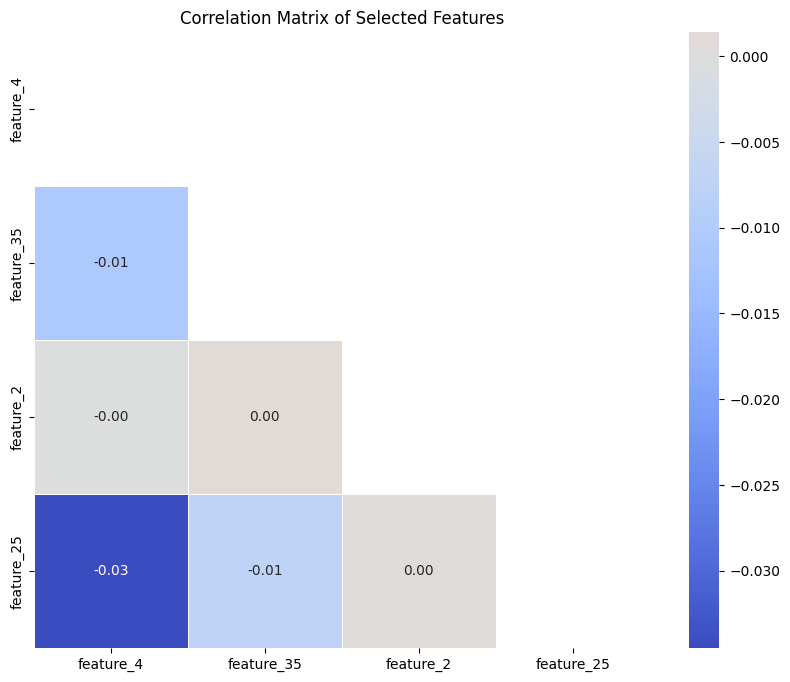

In [9]:
from copy import deepcopy
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from tqdm import tqdm
from joblib import Parallel, delayed
import warnings
warnings.filterwarnings('ignore')

# Example data setup (replace with your actual data)
np.random.seed(42)
n_samples, n_features = 1000, 50
X = pd.DataFrame(np.random.randn(n_samples, n_features), 
                 columns=[f'feature_{i}' for i in range(n_features)])
y = pd.Series(np.random.randint(0, 2, n_samples))

# Pipeline setup
nb_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('nb', GaussianNB())
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Configure caching to avoid recomputation
subset_cache = {}

# 2. Optimized evaluation function with caching
def evaluate_subset(cols):
    """Return F1 for NB on a subset with caching."""
    if not cols:  # Handle empty subset
        return 0.0
    
    key = frozenset(cols)
    if key in subset_cache:
        return subset_cache[key]
    
    try:
        score = cross_val_score(nb_pipe, X[list(cols)], y, cv=cv, 
                               scoring='f1', n_jobs=1).mean()
        subset_cache[key] = score
        return score
    except Exception as e:
        print(f"Error evaluating subset {cols}: {e}")
        return 0.0

# 3. Precompute base scores for individual features
print("Precomputing base feature scores...")
base_scores = {}
for f in tqdm(X.columns, desc="Computing base scores"):
    base_scores[f] = evaluate_subset([f])

# 4. Enhanced MCTS algorithm
root = set()
best_score = 0
features = list(X.columns)
history = []  # Track progress
feature_importance = {f: 0 for f in features}  # Track feature contributions

# Add progress bar
pbar = tqdm(range(20), desc="MCTS Feature Selection")
for round_ in pbar:
    candidates = [f for f in features if f not in root]
    if not candidates:
        break
    
    # Select random candidates
    n_candidates = min(8, len(candidates))
    selected_candidates = np.random.choice(candidates, size=n_candidates, replace=False)
    
    # Evaluate candidates sequentially (more stable than parallel for this case)
    scores = {}
    for f in selected_candidates:
        score = evaluate_subset(root | {f})
        scores[f] = score
    
    if not scores:  # No valid scores
        break
        
    f_star, s_star = max(scores.items(), key=lambda kv: kv[1])
    
    # Update feature importance (delta improvement)
    delta = s_star - best_score
    if delta > 0:
        feature_importance[f_star] += delta
    
    # Update if improvement
    if s_star > best_score:
        root.add(f_star)
        best_score = s_star
        history.append((round_, f_star, best_score, len(root)))
        pbar.set_description(f"Features: {len(root)} | F1: {best_score:.4f}")
    else:
        # Early stopping if no improvement for 3 rounds
        if history and (round_ - history[-1][0] > 2):
            break

# 5. Results summary
print("\n" + "="*50)
print(f"MCTS-selected {len(root)} features | F1 ≈ {best_score:.4f}")
print("Selected features:", list(root))

# ────────────────────
# Visualizations
# ────────────────────
plt.figure(figsize=(15, 10))

# A. Selection progress
plt.subplot(2, 2, 1)
if history:
    rounds, feats, scores, sizes = zip(*history)
    plt.plot(rounds, scores, 'o-', label='F1 Score')
    plt.plot(rounds, sizes, 's--', label='Feature Count')
    plt.xlabel('Round')
    plt.ylabel('Score/Count')
    plt.title('MCTS Selection Progress')
    plt.legend()
    plt.grid(True)
    
    # Annotate feature additions
    for r, f, s, _ in history:
        plt.annotate(f, (r, s), textcoords="offset points", 
                     xytext=(0,10), ha='center', fontsize=8)
else:
    plt.text(0.5, 0.5, 'No features selected', ha='center', va='center')
    plt.xlim(0, 1)
    plt.ylim(0, 1)

# B. Feature importance
plt.subplot(2, 2, 2)
imp_df = pd.DataFrame({
    'Feature': list(feature_importance.keys()),
    'Importance': list(feature_importance.values())
}).sort_values('Importance', ascending=False).head(20)

# Filter out zero importance features for plotting
imp_df_filtered = imp_df[imp_df['Importance'] > 0]

if not imp_df_filtered.empty:
    sns.barplot(x='Importance', y='Feature', data=imp_df_filtered, palette='viridis')
    plt.title('Feature Contribution to Improvement')
    plt.xlabel('Cumulative F1 Improvement')
else:
    plt.text(0.5, 0.5, 'No feature improvements found', ha='center', va='center')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.title('Feature Contribution to Improvement')

# C. Score distribution of candidates
plt.subplot(2, 2, 3)
if history and len(history) > 0:
    candidate_scores = []
    for r, f, s, size in history[:5]:  # Limit to first 5 rounds to avoid long computation
        round_candidates = [c for c in features if c not in {feat for _, feat, _, _ in history[:r+1]}]
        if round_candidates:
            # Sample a few candidates to avoid long computation
            sample_candidates = np.random.choice(round_candidates, 
                                               size=min(10, len(round_candidates)), 
                                               replace=False)
            round_scores = [evaluate_subset(root | {c}) for c in sample_candidates]
            candidate_scores.extend(round_scores)
    
    if candidate_scores:
        sns.histplot(candidate_scores, bins=min(20, len(candidate_scores)), kde=True)
        plt.axvline(x=best_score, color='r', linestyle='--', label='Best Score')
        plt.xlabel('F1 Score')
        plt.title('Candidate Subset Score Distribution')
        plt.legend()
    else:
        plt.text(0.5, 0.5, 'No candidate scores available', ha='center', va='center')
        plt.xlim(0, 1)
        plt.ylim(0, 1)
else:
    plt.text(0.5, 0.5, 'No history available', ha='center', va='center')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.title('Candidate Subset Score Distribution')

# D. Compare with baseline
plt.subplot(2, 2, 4)
baseline = evaluate_subset(list(X.columns))  # Full feature set
top_individual = max(base_scores.values()) if base_scores else 0

methods = ['Full Set', 'MCTS Subset', 'Top Individual']
scores = [baseline, best_score, top_individual]

plt.bar(methods, scores, color=['skyblue', 'lightgreen', 'salmon'])
plt.ylabel('F1 Score')
plt.title('Comparison with Baselines')
plt.ylim(0, max(scores)*1.1 if max(scores) > 0 else 1)

for i, v in enumerate(scores):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# 6. Final evaluation report
print("\nPerformance Comparison:")
print(f"- Full feature set ({X.shape[1]} features): F1 = {baseline:.4f}")
print(f"- MCTS selected ({len(root)} features): F1 = {best_score:.4f}")
print(f"- Best single feature: F1 = {top_individual:.4f}")
if len(root) > 0:
    print(f"Reduction: {X.shape[1] - len(root)} features ({100*(1-len(root)/X.shape[1]):.1f}% fewer)")
else:
    print("No features were selected by MCTS")

# 7. Feature correlation matrix (selected features)
if root and len(root) > 1:
    plt.figure(figsize=(10, 8))
    corr = X[list(root)].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
                center=0, square=True, linewidths=.5)
    plt.title('Correlation Matrix of Selected Features')
    plt.show()
elif root and len(root) == 1:
    print(f"\nOnly one feature selected: {list(root)[0]}")
    print("Cannot create correlation matrix with single feature.")
else:
    print("\nNo features selected. Cannot create correlation matrix.")

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import seaborn as sns


np.random.seed(42)
n_samples = 1000
X = np.random.randn(n_samples, 10)
y = np.random.randint(0, 2, n_samples)

# Example NB pipeline setup
nb_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('nb', GaussianNB())
])
nb_pipe.fit(X, y)

# Example MCMC posterior (replace with your actual MCMC results)
# Assuming posterior_f1 is a dictionary with 'yl' containing posterior samples
posterior_f1 = {
    'yl': np.random.rand(1000, n_samples)  # 1000 MCMC samples x n_samples predictions
}

# Hybrid ensemble – average NB + MCMC logistic posteriors

Computing hybrid ensemble predictions...
NB probabilities shape: (1000,)
MCMC probabilities shape: (1000,)

MODEL PERFORMANCE COMPARISON
Naive Bayes F1:     0.5473
MCMC Logistic F1:   0.5163
Hybrid Ensemble F1: 0.5420


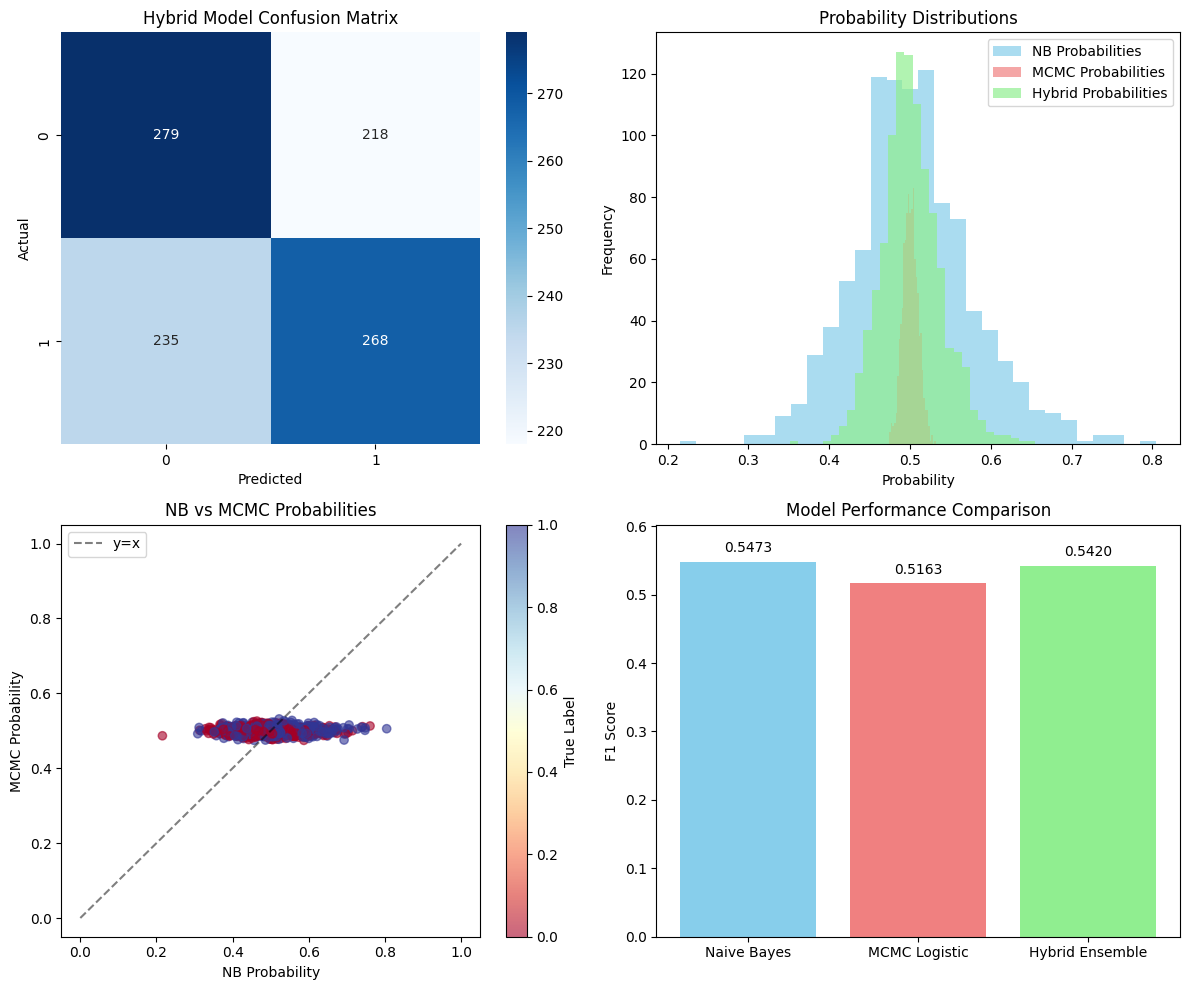


MODEL AGREEMENT ANALYSIS
Both models correct:         273 (27.3%)
Both models wrong:           212 (21.2%)
NB correct, MCMC wrong:      277 (27.7%)
MCMC correct, NB wrong:      238 (23.8%)

Hybrid improvement over best individual model: -0.0053

WEIGHT SENSITIVITY ANALYSIS
Weight NB=0.0, MCMC=1.0: F1 = 0.5163
Weight NB=0.1, MCMC=0.9: F1 = 0.5397
Weight NB=0.2, MCMC=0.8: F1 = 0.5405
Weight NB=0.3, MCMC=0.7: F1 = 0.5343
Weight NB=0.4, MCMC=0.6: F1 = 0.5385
Weight NB=0.5, MCMC=0.5: F1 = 0.5420
Weight NB=0.6, MCMC=0.4: F1 = 0.5464
Weight NB=0.7, MCMC=0.3: F1 = 0.5484
Weight NB=0.8, MCMC=0.2: F1 = 0.5475
Weight NB=0.9, MCMC=0.1: F1 = 0.5458
Weight NB=1.0, MCMC=0.0: F1 = 0.5473


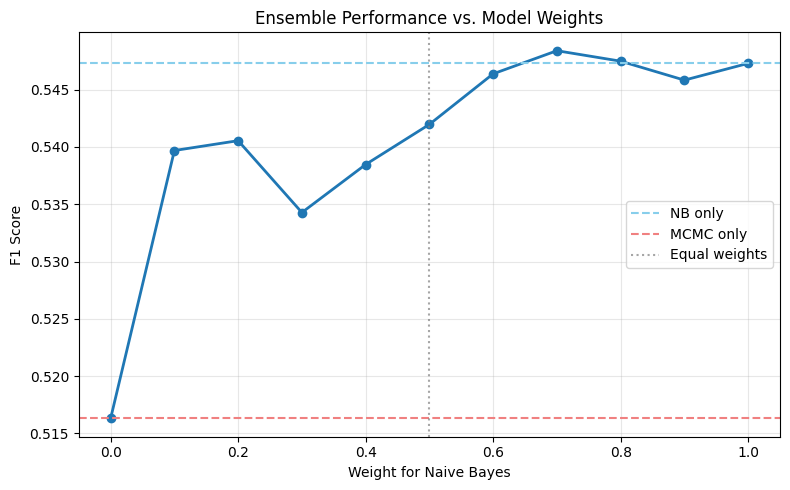


Optimal NB weight: 0.7 (F1 = 0.5484)


In [11]:


print("Computing hybrid ensemble predictions...")

# Get NB probabilities
nb_proba = nb_pipe.predict_proba(X)[:, 1]
print(f"NB probabilities shape: {nb_proba.shape}")

# Get MCMC probabilities (mean across posterior samples)
mcmc_proba = posterior_f1['yl'].mean(axis=0)
print(f"MCMC probabilities shape: {mcmc_proba.shape}")

# Ensure both probability arrays have the same length
assert len(nb_proba) == len(mcmc_proba), f"Length mismatch: NB={len(nb_proba)}, MCMC={len(mcmc_proba)}"

# Create hybrid predictions
hybrid_proba = 0.5 * nb_proba + 0.5 * mcmc_proba
y_hybrid = (hybrid_proba > 0.5).astype(int)

# Calculate individual model performance
y_nb = nb_pipe.predict(X)
y_mcmc = (mcmc_proba > 0.5).astype(int)

print("\n" + "="*50)
print("MODEL PERFORMANCE COMPARISON")
print("="*50)
print(f"Naive Bayes F1:     {f1_score(y, y_nb):.4f}")
print(f"MCMC Logistic F1:   {f1_score(y, y_mcmc):.4f}")
print(f"Hybrid Ensemble F1: {f1_score(y, y_hybrid):.4f}")

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Confusion Matrix for Hybrid Model
cm = confusion_matrix(y, y_hybrid)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title("Hybrid Model Confusion Matrix")
axes[0, 0].set_xlabel("Predicted")
axes[0, 0].set_ylabel("Actual")

# 2. Probability Distribution Comparison
axes[0, 1].hist(nb_proba, bins=30, alpha=0.7, label='NB Probabilities', color='skyblue')
axes[0, 1].hist(mcmc_proba, bins=30, alpha=0.7, label='MCMC Probabilities', color='lightcoral')
axes[0, 1].hist(hybrid_proba, bins=30, alpha=0.7, label='Hybrid Probabilities', color='lightgreen')
axes[0, 1].set_xlabel('Probability')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Probability Distributions')
axes[0, 1].legend()

# 3. Scatter plot: NB vs MCMC probabilities
scatter = axes[1, 0].scatter(nb_proba, mcmc_proba, c=y, cmap='RdYlBu', alpha=0.6)
axes[1, 0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='y=x')
axes[1, 0].set_xlabel('NB Probability')
axes[1, 0].set_ylabel('MCMC Probability')
axes[1, 0].set_title('NB vs MCMC Probabilities')
axes[1, 0].legend()
plt.colorbar(scatter, ax=axes[1, 0], label='True Label')

# 4. F1 Score Comparison
models = ['Naive Bayes', 'MCMC Logistic', 'Hybrid Ensemble']
f1_scores = [f1_score(y, y_nb), f1_score(y, y_mcmc), f1_score(y, y_hybrid)]
colors = ['skyblue', 'lightcoral', 'lightgreen']

bars = axes[1, 1].bar(models, f1_scores, color=colors)
axes[1, 1].set_ylabel('F1 Score')
axes[1, 1].set_title('Model Performance Comparison')
axes[1, 1].set_ylim(0, max(f1_scores) * 1.1)

# Add value labels on bars
for bar, score in zip(bars, f1_scores):
    height = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                   f'{score:.4f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Additional analysis: Agreement between models
agreement_both_correct = np.sum((y_nb == y) & (y_mcmc == y))
agreement_both_wrong = np.sum((y_nb != y) & (y_mcmc != y))
nb_correct_mcmc_wrong = np.sum((y_nb == y) & (y_mcmc != y))
mcmc_correct_nb_wrong = np.sum((y_nb != y) & (y_mcmc == y))

print("\n" + "="*50)
print("MODEL AGREEMENT ANALYSIS")
print("="*50)
print(f"Both models correct:        {agreement_both_correct:4d} ({100*agreement_both_correct/len(y):.1f}%)")
print(f"Both models wrong:          {agreement_both_wrong:4d} ({100*agreement_both_wrong/len(y):.1f}%)")
print(f"NB correct, MCMC wrong:     {nb_correct_mcmc_wrong:4d} ({100*nb_correct_mcmc_wrong/len(y):.1f}%)")
print(f"MCMC correct, NB wrong:     {mcmc_correct_nb_wrong:4d} ({100*mcmc_correct_nb_wrong/len(y):.1f}%)")

# Ensemble benefit analysis
hybrid_improvement = f1_score(y, y_hybrid) - max(f1_score(y, y_nb), f1_score(y, y_mcmc))
print(f"\nHybrid improvement over best individual model: {hybrid_improvement:+.4f}")

# Weight sensitivity analysis
print("\n" + "="*50)
print("WEIGHT SENSITIVITY ANALYSIS")
print("="*50)
weights = np.arange(0, 1.1, 0.1)
f1_scores_weighted = []

for w in weights:
    hybrid_w = w * nb_proba + (1-w) * mcmc_proba
    y_hybrid_w = (hybrid_w > 0.5).astype(int)
    f1_w = f1_score(y, y_hybrid_w)
    f1_scores_weighted.append(f1_w)
    print(f"Weight NB={w:.1f}, MCMC={1-w:.1f}: F1 = {f1_w:.4f}")

# Plot weight sensitivity
plt.figure(figsize=(8, 5))
plt.plot(weights, f1_scores_weighted, 'o-', linewidth=2, markersize=6)
plt.axhline(y=f1_score(y, y_nb), color='skyblue', linestyle='--', label='NB only')
plt.axhline(y=f1_score(y, y_mcmc), color='lightcoral', linestyle='--', label='MCMC only')
plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.7, label='Equal weights')
plt.xlabel('Weight for Naive Bayes')
plt.ylabel('F1 Score')
plt.title('Ensemble Performance vs. Model Weights')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

optimal_weight = weights[np.argmax(f1_scores_weighted)]
print(f"\nOptimal NB weight: {optimal_weight:.1f} (F1 = {max(f1_scores_weighted):.4f})")